### Understanding Data

In [1]:
import pandas as pd

df = pd.read_csv(r"C:\Users\JAHNAVI\OneDrive\Desktop\fraud D\card_transdata.csv")
df = df.sample(n=10000, random_state=42)

print(df.shape)
df.head()

(10000, 8)


,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
987231,0.929509,1.296477,0.361110,0.0,0.0,0.0,1.0,0.0
79954,0.611179,0.208295,3.118884,0.0,0.0,0.0,1.0,0.0
567130,3.956062,0.529194,1.579942,1.0,0.0,0.0,0.0,0.0
500891,21.798902,0.019399,11.416909,1.0,0.0,0.0,0.0,0.0
55399,3.310635,1.707802,2.028915,1.0,0.0,0.0,0.0,0.0


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10000 entries, 987231 to 551383
Data columns (total 8 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   distance_from_home              10000 non-null  float64
 1   distance_from_last_transaction  10000 non-null  float64
 2   ratio_to_median_purchase_price  10000 non-null  float64
 3   repeat_retailer                 10000 non-null  float64
 4   used_chip                       10000 non-null  float64
 5   used_pin_number                 10000 non-null  float64
 6   online_order                    10000 non-null  float64
 7   fraud                           10000 non-null  float64
dtypes: float64(8)
memory usage: 703.1 KB


In [3]:
df.shape

(10000, 8)

In [4]:
df.columns

Index(['distance_from_home', 'distance_from_last_transaction',
       'ratio_to_median_purchase_price', 'repeat_retailer', 'used_chip',
       'used_pin_number', 'online_order', 'fraud'],
      dtype='object')

In [5]:
df.describe()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,25.081686,5.353133,1.808808,0.878500,0.355400,0.099800,0.651600,0.083000
std,54.344275,24.197769,2.787740,0.326724,0.478658,0.299748,0.476487,0.275896
min,0.051745,0.002064,0.015832,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.721013,0.304724,0.474840,1.000000,0.000000,0.000000,0.000000,0.000000
50%,9.628086,1.008983,0.990146,1.000000,0.000000,0.000000,1.000000,0.000000
75%,25.244026,3.371965,2.077844,1.000000,1.000000,0.000000,1.000000,0.000000
max,2128.447706,885.429012,64.549528,1.000000,1.000000,1.000000,1.000000,1.000000


### Cleaning the Data

In [6]:
df.isnull().sum()

distance_from_home                0
distance_from_last_transaction    0
ratio_to_median_purchase_price    0
repeat_retailer                   0
used_chip                         0
used_pin_number                   0
online_order                      0
fraud                             0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

### SEPARATE FEATURES & TARGET

In [8]:
X = df.drop("fraud", axis=1)
y = df["fraud"]

### SCALING

In [9]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

cols_to_scale = ["distance_from_home","distance_from_last_transaction","ratio_to_median_purchase_price"]

X[cols_to_scale] = scaler.fit_transform(X[cols_to_scale])

### TRAIN-TEST SPLIT

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

### LOGISTIC REGRESSION

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import cross_val_score, GridSearchCV
import seaborn as sns
import matplotlib.pyplot as plt

In [12]:
lr = LogisticRegression()
lr.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [13]:
y_pred_lr = lr.predict(X_test)
print("Logistic Accuracy:", accuracy_score(y_test, y_pred_lr))

Logistic Accuracy: 0.9525


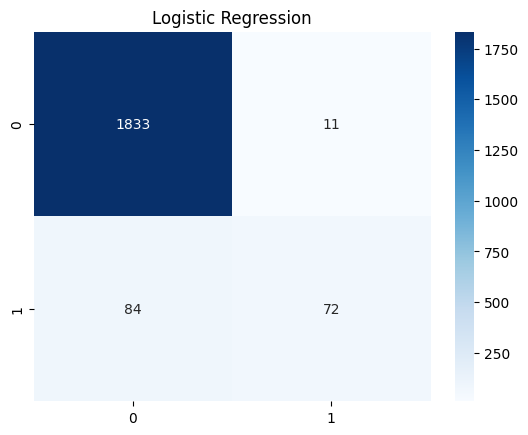

In [14]:
cm = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Logistic Regression")
plt.show()

In [15]:
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

         0.0       0.96      0.99      0.97      1844
         1.0       0.87      0.46      0.60       156

    accuracy                           0.95      2000
   macro avg       0.91      0.73      0.79      2000
weighted avg       0.95      0.95      0.95      2000



In [16]:
cv_lr = cross_val_score(lr, X_train, y_train, cv=5)
print("CV Score:", cv_lr.mean())

CV Score: 0.9497500000000001


In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

best_score = 0
best_C = None

for c in [0.1, 1, 10]:
    model = LogisticRegression(C=c, max_iter=1000)
    model.fit(X_train, y_train)
    
    score = model.score(X_test, y_test)
    
    if score > best_score:
        best_score = score
        best_C = c

print("Best C:", best_C)

# Final model
best_lr = LogisticRegression(C=best_C, max_iter=1000)
best_lr.fit(X_train, y_train)

# Accuracy
print("Tuned Accuracy:", accuracy_score(y_test, best_lr.predict(X_test)))

Best C: 10
Tuned Accuracy: 0.955


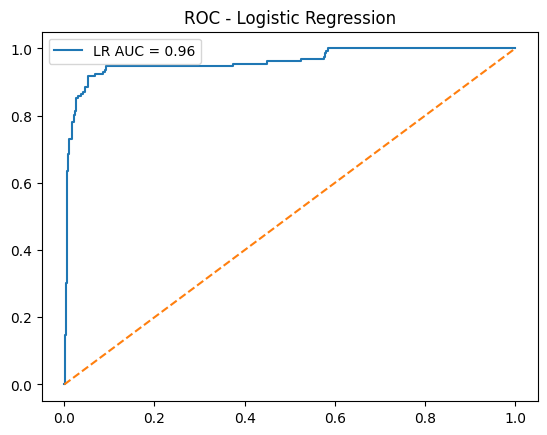

In [18]:
from sklearn.metrics import roc_curve, auc

y_prob_lr = best_lr.predict_proba(X_test)[:,1]
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
roc_auc_lr = auc(fpr_lr, tpr_lr)

plt.plot(fpr_lr, tpr_lr, label=f"LR AUC = {roc_auc_lr:.2f}")
plt.plot([0,1], [0,1], linestyle='--')
plt.title("ROC - Logistic Regression")
plt.legend()
plt.show()

### RANDOM FOREST

In [19]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier()
rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [20]:
y_pred_rf = rf.predict(X_test)

print("RF Accuracy:", accuracy_score(y_test, y_pred_rf))

RF Accuracy: 0.998


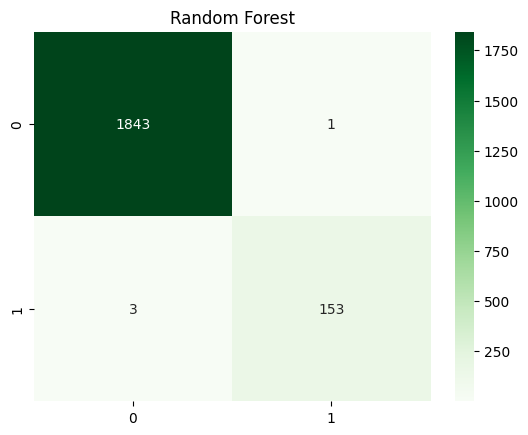

In [21]:
cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens')
plt.title("Random Forest")
plt.show()

In [22]:
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      1844
         1.0       0.99      0.98      0.99       156

    accuracy                           1.00      2000
   macro avg       1.00      0.99      0.99      2000
weighted avg       1.00      1.00      1.00      2000



In [23]:
cv_rf = cross_val_score(rf, X_train, y_train, cv=5)
print("CV Score:", cv_rf.mean())

CV Score: 0.99725


In [24]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

best_score = 0
best_params = {}

for n in [100, 200]:
    for d in [None, 5, 10]:
        
        model = RandomForestClassifier(
            n_estimators=n,
            max_depth=d,
            class_weight='balanced',   # important for fraud
            random_state=42
        )
        
        model.fit(X_train, y_train)
        score = model.score(X_test, y_test)
        
        if score > best_score:
            best_score = score
            best_params = {'n_estimators': n, 'max_depth': d}

print("Best Params:", best_params)

# Final model
best_rf = RandomForestClassifier(
    n_estimators=best_params['n_estimators'],
    max_depth=best_params['max_depth'],
    class_weight='balanced',
    random_state=42
)

best_rf.fit(X_train, y_train)

print("Tuned Accuracy:", accuracy_score(y_test, best_rf.predict(X_test)))

Best Params: {'n_estimators': 100, 'max_depth': 5}
Tuned Accuracy: 0.998


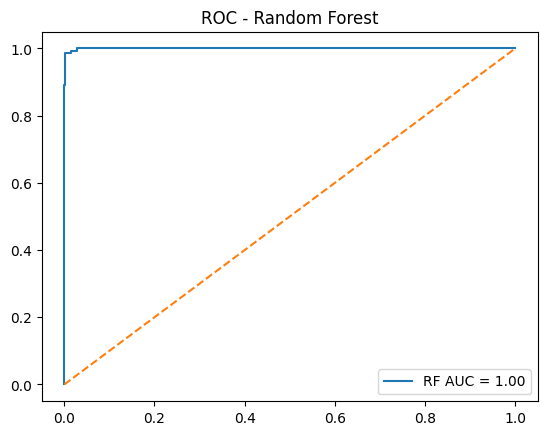

In [25]:
y_prob_rf = best_rf.predict_proba(X_test)[:,1]
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
roc_auc_rf = auc(fpr_rf, tpr_rf)

plt.plot(fpr_rf, tpr_rf, label=f"RF AUC = {roc_auc_rf:.2f}")
plt.plot([0,1], [0,1], linestyle='--')
plt.title("ROC - Random Forest")
plt.legend()
plt.show()

### SVC

In [26]:
from sklearn.svm import SVC

svm = SVC(probability=True)
svm.fit(X_train, y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,True
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [27]:
y_pred_svm = svm.predict(X_test)
print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))

SVM Accuracy: 0.988


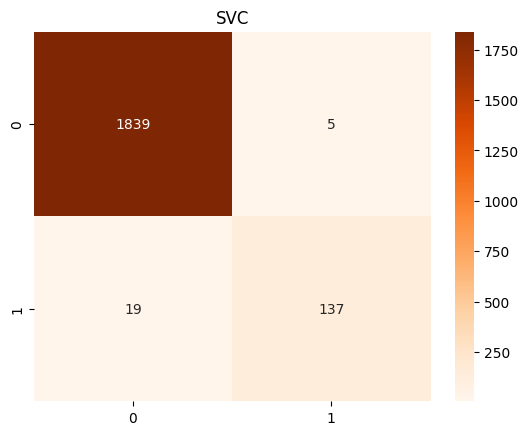

In [28]:
cm = confusion_matrix(y_test, y_pred_svm)
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges')
plt.title("SVC")
plt.show()

In [29]:
print(classification_report(y_test, y_pred_svm))

              precision    recall  f1-score   support

         0.0       0.99      1.00      0.99      1844
         1.0       0.96      0.88      0.92       156

    accuracy                           0.99      2000
   macro avg       0.98      0.94      0.96      2000
weighted avg       0.99      0.99      0.99      2000



In [30]:
cv_svm = cross_val_score(svm, X_train, y_train, cv=5)
print("CV Score:", cv_svm.mean())

CV Score: 0.9870000000000001


In [31]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

best_score = 0
best_params = {}

for c in [0.1, 1, 10]:
    for k in ['linear', 'rbf']:
        
        model = SVC(
            C=c,
            kernel=k,
            probability=True
        )
        
        model.fit(X_train, y_train)
        score = model.score(X_test, y_test)
        
        if score > best_score:
            best_score = score
            best_params = {'C': c, 'kernel': k}

print("Best Params:", best_params)

# Final model
best_svm = SVC(
    C=best_params['C'],
    kernel=best_params['kernel'],
    probability=True
)

best_svm.fit(X_train, y_train)

print("Tuned Accuracy:", accuracy_score(y_test, best_svm.predict(X_test)))

Best Params: {'C': 10, 'kernel': 'rbf'}
Tuned Accuracy: 0.993


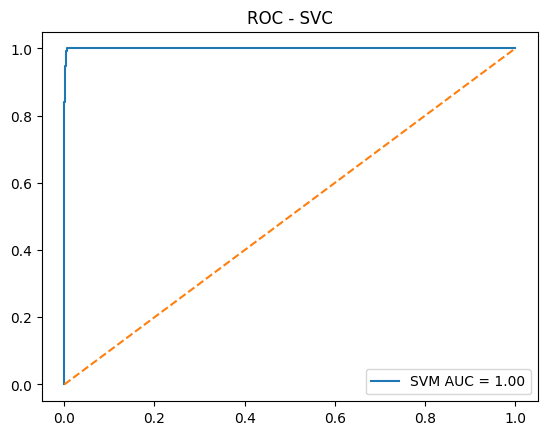

In [32]:
y_prob_svm = best_svm.predict_proba(X_test)[:,1]
fpr_svm, tpr_svm, _ = roc_curve(y_test, y_prob_svm)
roc_auc_svm = auc(fpr_svm, tpr_svm)

plt.plot(fpr_svm, tpr_svm, label=f"SVM AUC = {roc_auc_svm:.2f}")
plt.plot([0,1], [0,1], linestyle='--')
plt.title("ROC - SVC")
plt.legend()
plt.show()

### DECISION TREE

In [33]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier()
dt.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [34]:
y_pred_dt = dt.predict(X_test)

print("DT Accuracy:", accuracy_score(y_test, y_pred_dt))

DT Accuracy: 0.9985


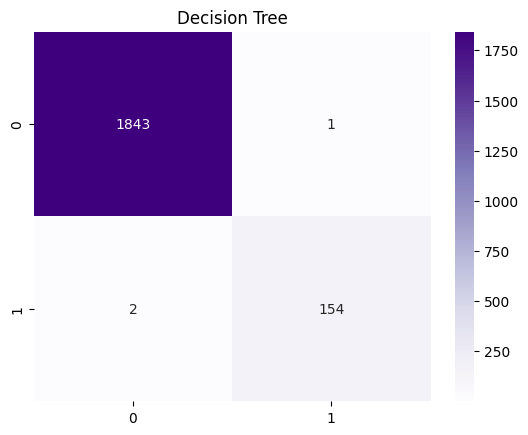

In [35]:
cm = confusion_matrix(y_test, y_pred_dt)
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples')
plt.title("Decision Tree")
plt.show()

In [36]:
cv_dt = cross_val_score(dt, X_train, y_train, cv=5)
print("CV Score:", cv_dt.mean())

CV Score: 0.9974999999999999


In [37]:
param_dt = {
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5, 10]
}
grid_dt = GridSearchCV(DecisionTreeClassifier(), param_dt, cv=5)
grid_dt.fit(X_train, y_train)

print("Best Params:", grid_dt.best_params_)

best_dt = grid_dt.best_estimator_

Best Params: {'max_depth': None, 'min_samples_split': 2}


In [38]:
print("Tuned Accuracy:", accuracy_score(y_test, best_dt.predict(X_test)))

Tuned Accuracy: 0.998


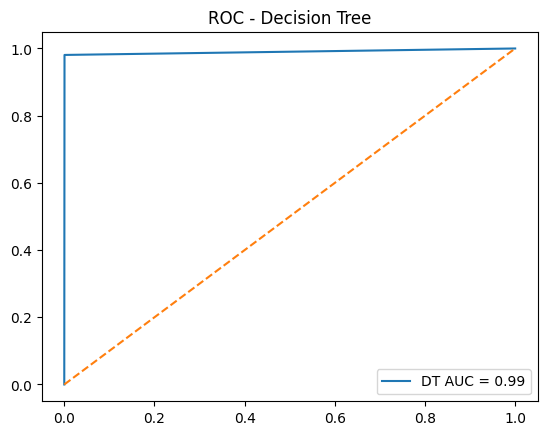

In [39]:
y_prob_dt = best_dt.predict_proba(X_test)[:,1]
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)
roc_auc_dt = auc(fpr_dt, tpr_dt)

plt.plot(fpr_dt, tpr_dt, label=f"DT AUC = {roc_auc_dt:.2f}")
plt.plot([0,1], [0,1], linestyle='--')
plt.title("ROC - Decision Tree")
plt.legend()
plt.show()

### MODEL COMPARISON

In [40]:
from sklearn.metrics import accuracy_score

lr_acc = accuracy_score(y_test, best_lr.predict(X_test))
rf_acc = accuracy_score(y_test, best_rf.predict(X_test))
dt_acc = accuracy_score(y_test, best_dt.predict(X_test))
svm_acc = accuracy_score(y_test, best_svm.predict(X_test))

print("Logistic:", lr_acc)
print("Random Forest:", rf_acc)
print("Decision Tree:", dt_acc)
print("SVM:", svm_acc)

Logistic: 0.955
Random Forest: 0.998
Decision Tree: 0.998
SVM: 0.993


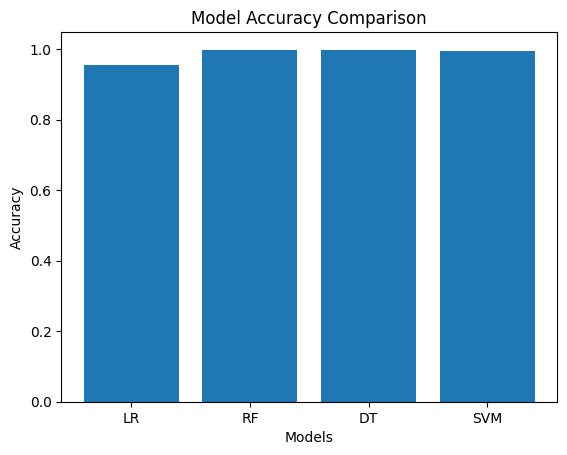

In [41]:
import matplotlib.pyplot as plt

models = ['LR', 'RF', 'DT', 'SVM']
accuracy = [lr_acc, rf_acc, dt_acc, svm_acc]

plt.bar(models, accuracy)
plt.title("Model Accuracy Comparison")
plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.show()

### Model Deployement

In [42]:
import joblib

joblib.dump(model, "fraud_detection_model.pkl")

['fraud_detection_model.pkl']

In [43]:
joblib.dump(rf, "fraud_detection_model.pkl")

['fraud_detection_model.pkl']

In [44]:
import gradio as gr
import numpy as np
import joblib

# Load model
model = joblib.load("fraud_detection_model.pkl")

# Prediction function
def predict_fraud(
    distance_from_home,
    distance_from_last_transaction,
    ratio_to_median_purchase_price,
    repeat_retailer,
    used_chip,
    used_pin_number,
    online_order
):

    features = np.array([[ 
        distance_from_home,
        distance_from_last_transaction,
        ratio_to_median_purchase_price,
        repeat_retailer,
        used_chip,
        used_pin_number,
        online_order
    ]])

    prediction = model.predict(features)

    if prediction[0] == 1:
        return " Fraudulent Transaction"
    else:
        return " Legitimate Transaction"

# Gradio UI
demo = gr.Interface(
    fn=predict_fraud,

    inputs=[
        gr.Number(label="Distance From Home"),
        gr.Number(label="Distance From Last Transaction"),
        gr.Number(label="Ratio To Median Purchase Price"),
        gr.Radio([0,1], label="Repeat Retailer"),
        gr.Radio([0,1], label="Used Chip"),
        gr.Radio([0,1], label="Used PIN Number"),
        gr.Radio([0,1], label="Online Order")
    ],

    outputs=gr.Textbox(label="Prediction"),

    title="Credit Card Fraud Detection System",

    description="Enter transaction details to predict whether transaction is Fraud or Legitimate."
)

demo.launch()

C:\Users\JAHNAVI\anaconda3\envs\Jahnavi\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.
